In [ ]:
# Environnement : en local, lancer le notebook depuis la racine du depot.
# Sur Google Colab, on clone le depot puis on se place dedans.
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('models'):
    os.system('git clone https://github.com/AISSAOUI-15/generative-image-reconstruction.git')
    os.chdir('generative-image-reconstruction')

In [ ]:
from __future__ import print_function
import matplotlib.pyplot as plt
%matplotlib inline

import os
#os.environ['CUDA_VISIBLE_DEVICES'] = '1'

import numpy as np
from models.resnet import ResNet
from models.unet import UNet
from models.skip import skip
from models import get_net
import torch
import torch.optim
from skimage.metrics import peak_signal_noise_ratio
import torch.nn.functional as F

from utils.inpainting_utils import *

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark =True
dtype = torch.cuda.FloatTensor

PLOT = True
imsize=-1
dim_div_by = 64
dtype = torch.cuda.FloatTensor

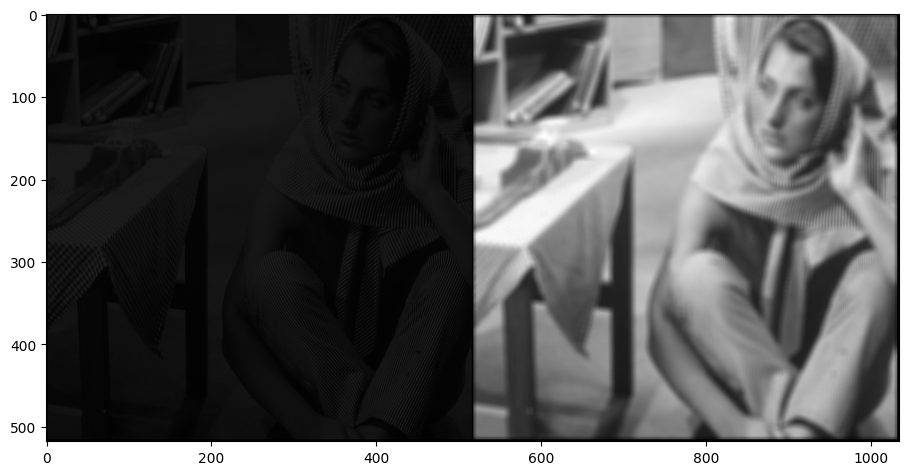

array([[[0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.7764706 , ..., 1.0657952 ,
         0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.38039216, ..., 1.219608  ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ]],

       [[0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.7764706 , ..., 1.0657952 ,
         0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.38039216, ..., 1.219608  ,
         0.        , 0.        ],
        [0. 

In [ ]:
f = './data/restoration/barbara.png'

img_pil, img_np = get_image(f, imsize)

img_np = nn.ReflectionPad2d(1)(np_to_torch(img_np))[0].numpy()
img_pil = np_to_pil(img_np)

kernel = torch.ones(1, 1, 9, 9) /9.0  # Filtre moyenneur 3x3
# No need to unsqueeze the dimensions here

# Conversion des images en tensors
img_var = torch.from_numpy(img_np).unsqueeze(0).type(torch.FloatTensor)

# Application de la convolution
img_convolved = F.conv2d(img_var, kernel, padding='same')  # Added padding to match ReflectionPad2d
img_conv = torch_to_np(img_convolved)
# Affichage des images
plot_image_grid([img_np, img_conv], 3, 9)


In [ ]:
img_convolved.shape

torch.Size([1, 1, 514, 514])

In [ ]:
show_every=1000
figsize=5
pad = 'reflection' # 'zero'
INPUT = 'noise'
input_depth = 32
OPTIMIZER = 'adam'
OPT_OVER =  'net'


LR = 0.001
num_iter = 4000
reg_noise_std = 0.03

net = UNet(num_input_channels=input_depth, num_output_channels=1,
                   feature_scale=8, more_layers=1,
                   concat_x=False, upsample_mode='deconv',
                   pad='zero', norm_layer=torch.nn.InstanceNorm2d, need_sigmoid=True, need_bias=True)


# Loss
mse = torch.nn.MSELoss().type(dtype)
img_var = np_to_torch(img_np).type(dtype)

net_input = get_noise(input_depth, INPUT, img_np.shape[1:]).type(dtype).detach()

zero
zero
zero
zero
zero
zero
zero
zero
zero
zero
zero


In [ ]:
net_input.shape

torch.Size([1, 32, 514, 514])

In [ ]:
if torch.cuda.is_available():
    net.cuda()
out = net(net_input)

In [ ]:
out.shape

torch.Size([1, 1, 512, 512])

In [ ]:
from skimage.transform import resize
img_np = resize(img_np, (1, 512, 512), mode='constant')

In [ ]:
img_np.shape

(1, 512, 512)

Starting optimization with ADAM


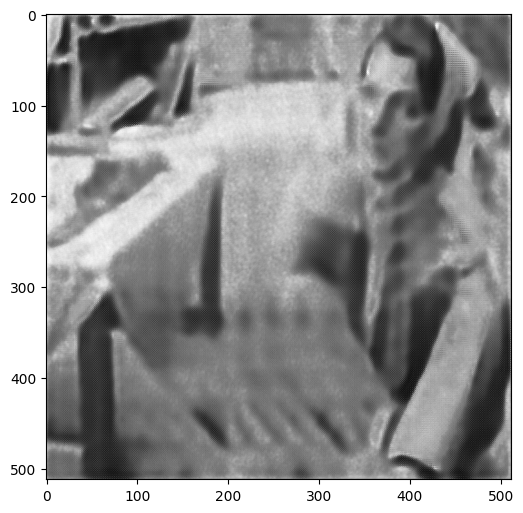

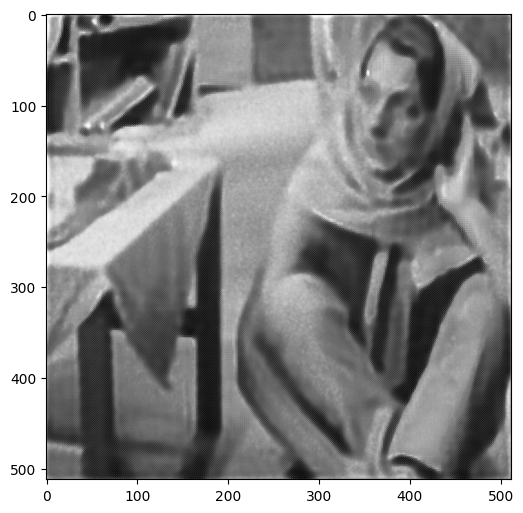

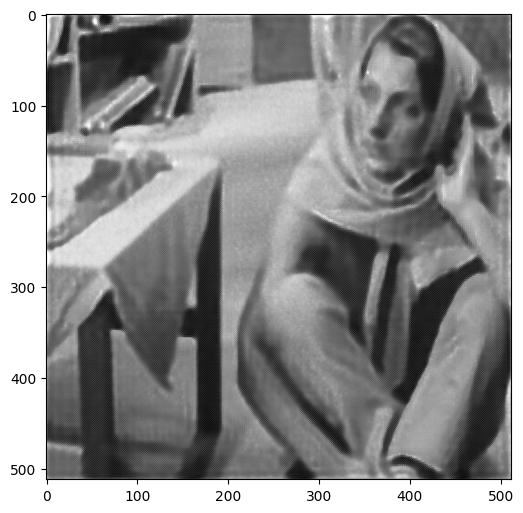

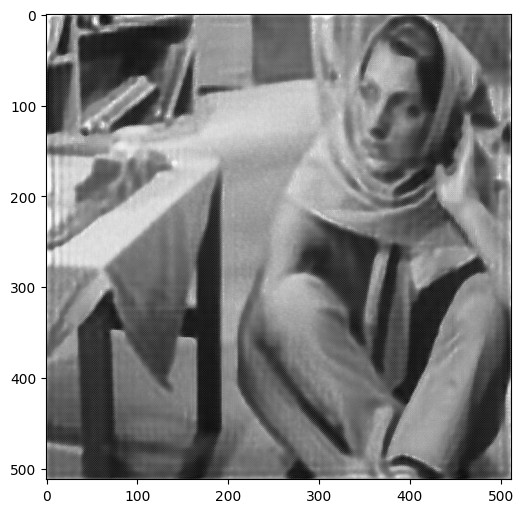

In [ ]:
from skimage.metrics import mean_squared_error
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
kernel = kernel.to(device)
img_convolved = img_convolved.to(device)
Iter_loss = []
def closure():

    global i, psrn_masked_last, last_net, net_input

    if reg_noise_std > 0:
        net_input = net_input_saved + (noise.normal_() * reg_noise_std)
    net_input = net_input.to(device)
    if torch.cuda.is_available():
        net.cuda()
    out = net(net_input)

    conv_i = F.conv2d(out, kernel, padding=5)
    total_loss = mse( conv_i , img_convolved)
    Iter_mse = mean_squared_error(out.detach().cpu().numpy()[0], img_np)
    Iter_loss.append(Iter_mse)
    total_loss.backward()

    psrn_masked = peak_signal_noise_ratio(img_conv, torch_to_np(conv_i), data_range=10)
    # psrn = peak_signal_noise_ratio(img_np, out.detach().cpu().numpy()[0])

    # print ('Iteration %05d    Loss %f PSNR_masked %f PSNR %f' % (i, total_loss.item(), psrn_masked, psrn),'\r', end='')


    if  PLOT and i % show_every == 0:
        out_np = torch_to_np(out)

        # Backtracking
        if psrn_masked - psrn_masked_last < -5:
            print('Falling back to previous checkpoint.')

            for new_param, net_param in zip(last_net, net.parameters()):
                net_param.data.copy_(new_param.cuda())

            return total_loss*0
        else:
            last_net = [x.cpu() for x in net.parameters()]
            psrn_masked_last = psrn_masked



        plot_image_grid([np.clip(out_np, 0, 1)], factor=figsize, nrow=1)

    i += 1

    return total_loss

# Init globals
last_net = None
psrn_masked_last = 0
i = 0

net_input_saved = net_input.detach().clone()
noise = net_input.detach().clone()

# Run
p = get_params(OPT_OVER, net, net_input)
optimize(OPTIMIZER, p, closure, LR=LR, num_iter=num_iter)

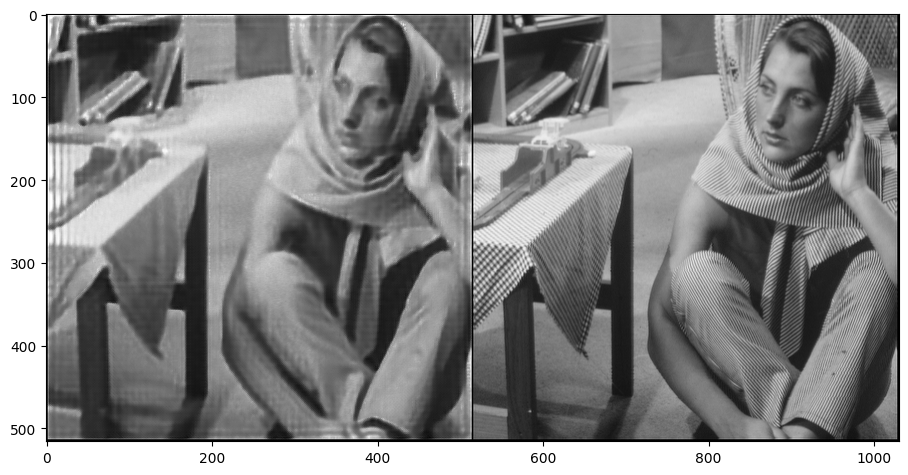

In [ ]:
out_np = torch_to_np(net(net_input))
q = plot_image_grid([np.clip(out_np, 0, 1), img_np], factor=9);

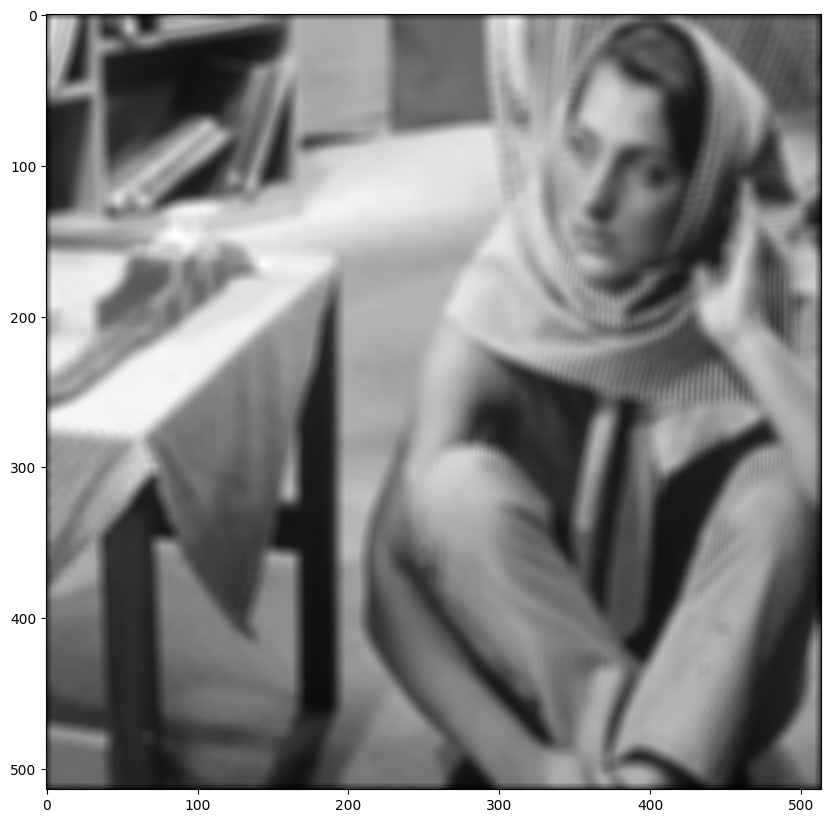

In [ ]:
q = plot_image_grid([img_conv], factor=9);

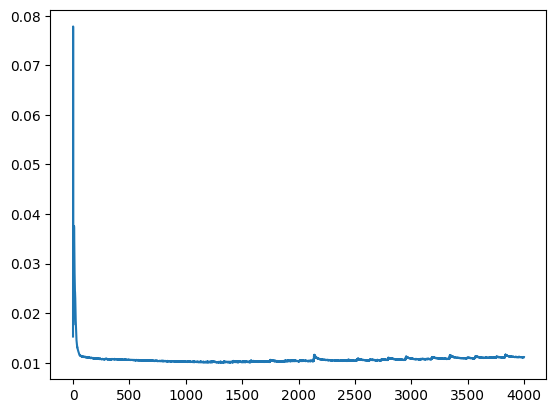

In [ ]:
plt.plot(Iter_loss)

In [ ]:
from skimage.metrics import structural_similarity as ssim
# Initialiser une liste pour stocker les valeurs SSIM pour chaque canal
ssim_values = []

# Calculer SSIM pour chaque canal
for i in range(img_np.shape[0]):
    ssim_channel = ssim(img_np[i], out_np[i], data_range=out_np.max() - out_np.min())
    ssim_values.append(ssim_channel)

# Calculer la moyenne des valeurs SSIM pour chaque canal
ssim_mean = np.mean(ssim_values)

print("SSIM moyen  :", ssim_mean)

SSIM moyen  : 0.3794868454278893


In [ ]:
img_np = img_np.squeeze()
out_np = out_np.squeeze()
mse = np.mean((img_np - out_np) ** 2)
mse

0.01108759

In [ ]:
img_np.shape

(512, 512)